## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Will Keenan

**Date:** 10/12/2026

In [ ]:
#Question 1.1
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

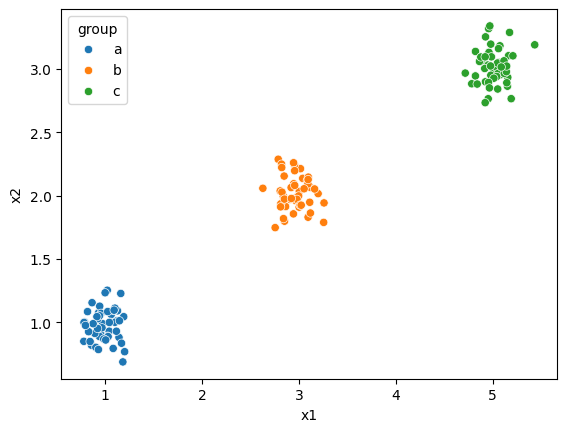

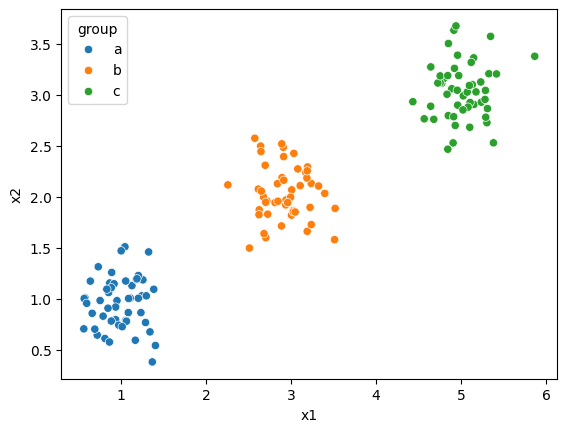

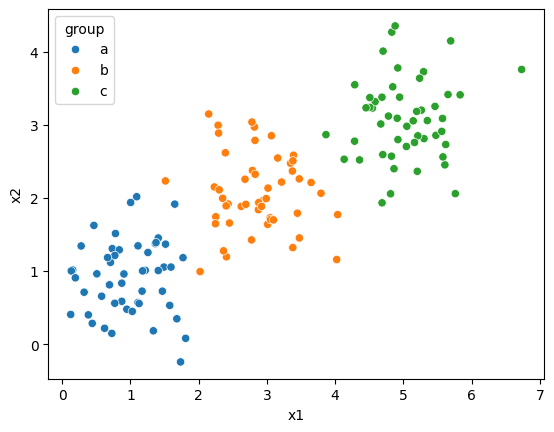

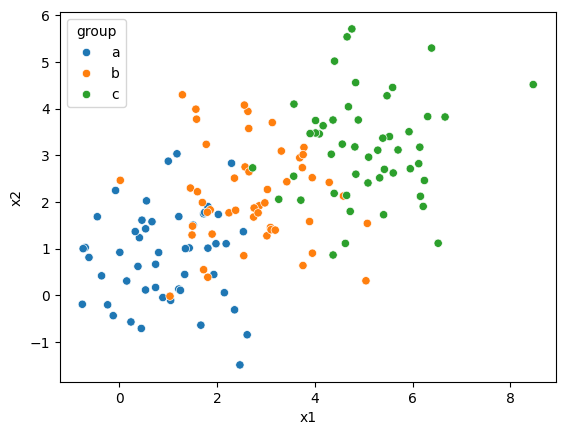

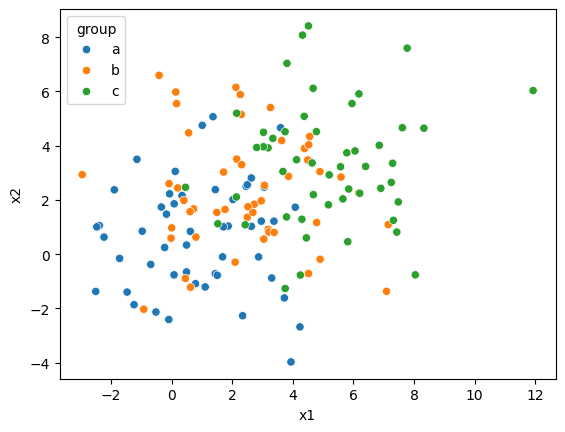

In [ ]:
#Question 1.2:
import seaborn as sns
import matplotlib.pyplot as plt

for df in [df0_125, df0_25, df0_5, df1_0, df2_0]:
    sns.scatterplot(data=df, x='x1', y='x2', hue='group')
    plt.show()

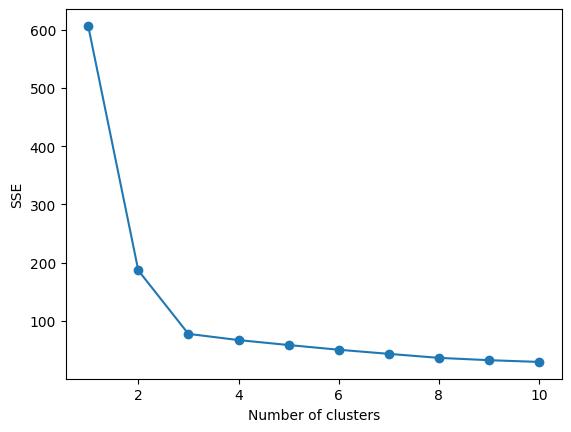

In [ ]:
#Question 1.3
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

SSE = [KMeans(n_clusters=k, n_init=10, random_state=100).fit(df0_5[['x1', 'x2']]).inertia_
       for k in range(1, 11)]
plt.plot(range(1, 11), SSE, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('SSE')
plt.show()

In [ ]:
#Question 1.4
'''
The numerical significance of the elbow is where the PCA curve starts to flatten out.
If the elbow occurs at 3 clusters, for example, then you can reasonably assume that
you only need those three clusters to explain a large amount of variance in the data.
Including any more clusters would lead to overfitting and poor performance outside of the
training dataset.
'''

In [6]:
#Question 2.1
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, classification_report
!git clone https://github.com/willhk10-uva/A04-clustering
df = pd.read_csv('A04-clustering/data/SIPRI Military Expenditure Database.csv')
df = df.loc[df['Year'] == 2020, :]
df = df.dropna()
print(df.shape)
print(df.dtypes)
df.describe()

fatal: destination path 'A04-clustering' already exists and is not an empty directory.
(148, 7)
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object


,index,Year,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
count,148.000000,148.0,148.000000,148.000000,148.000000,148.000000
mean,2831.256757,2020.0,13153.747670,0.019619,0.061510,268.264494
std,1654.299355,0.0,68005.236120,0.015033,0.046207,430.434878
min,32.000000,2020.0,8.622460,0.000054,0.004896,0.580129
25%,1409.000000,2020.0,204.877177,0.010413,0.031352,20.553464
50%,2871.000000,2020.0,959.535443,0.015324,0.047402,81.506703
75%,4222.500000,2020.0,5289.998320,0.024327,0.084681,326.267753
max,5880.000000,2020.0,778397.200000,0.098470,0.303027,2520.398541


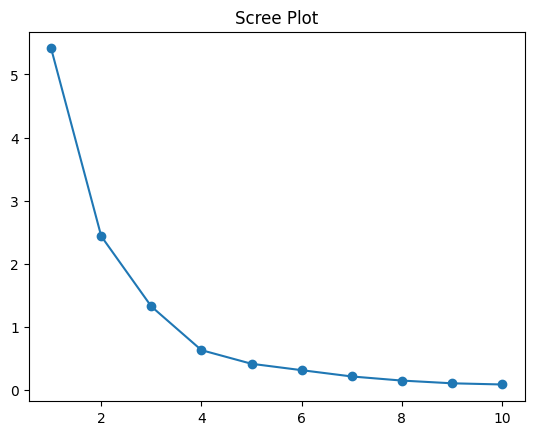

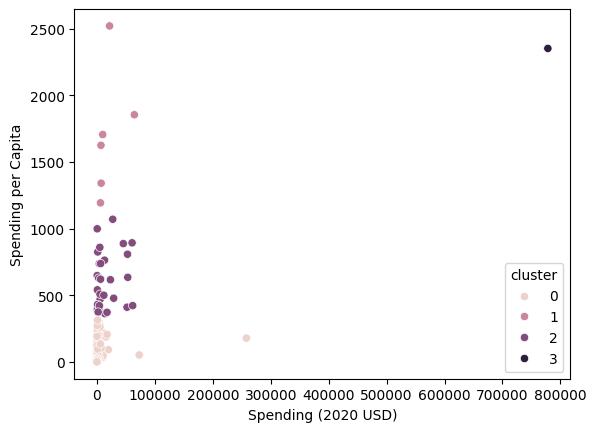

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,3


In [7]:
#Question 2.2
X = df[['Spending (2020 USD)', 'Spending per Capita']]
X = (X - X.min()) / (X.max() - X.min())

SSE = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10).fit(X)
    SSE.append(model.inertia_)
plt.plot(range(1, 11), SSE, marker='o')
plt.title('Scree Plot')
plt.show()

model = KMeans(n_clusters=4, n_init=10).fit(X)
df['cluster'] = model.labels_

sns.scatterplot(data=df, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster')
plt.show()

df.groupby('cluster')[['Spending (2020 USD)', 'Spending per Capita']].describe()
df[df['Country'] == 'United States of America']

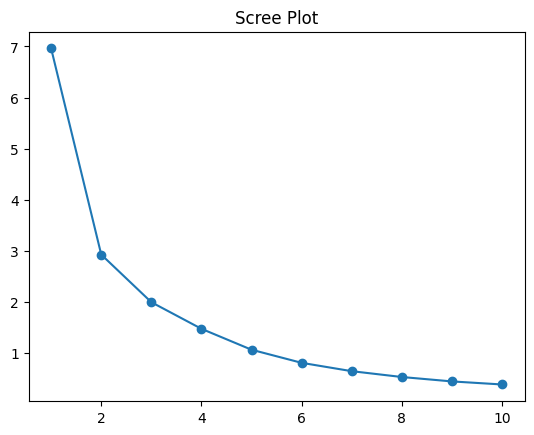

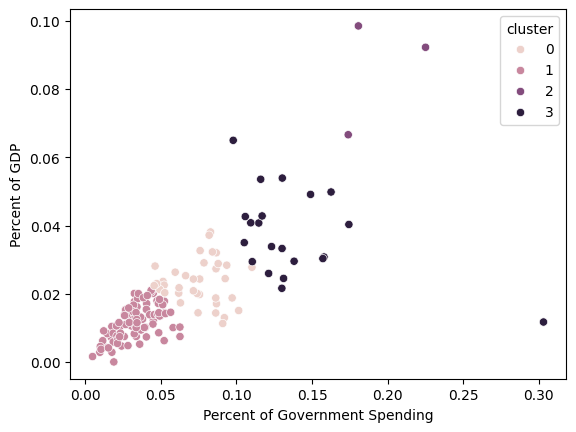

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,cluster
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,0


In [9]:
#Question 2.3
X = df[['Percent of Government Spending', 'Percent of GDP']]
X = (X - X.min()) / (X.max() - X.min())

SSE = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10).fit(X)
    SSE.append(model.inertia_)
plt.plot(range(1, 11), SSE, marker='o')
plt.title('Scree Plot')
plt.show()

model = KMeans(n_clusters=4, n_init=10).fit(X)
df['cluster'] = model.labels_

sns.scatterplot(data=df, x='Percent of Government Spending', y='Percent of GDP', hue='cluster')
plt.show()

df.groupby('cluster')[['Percent of Government Spending', 'Percent of GDP']].describe()
df[df['Country'] == 'United States of America']

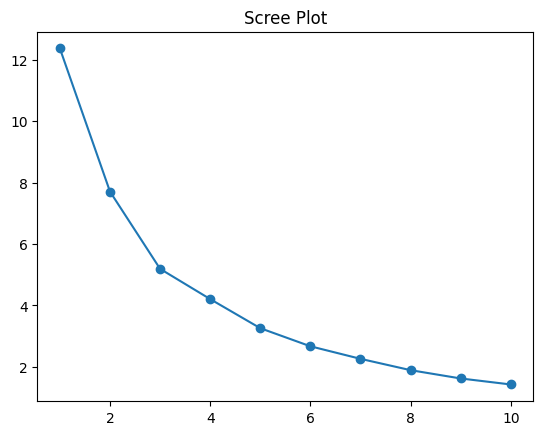

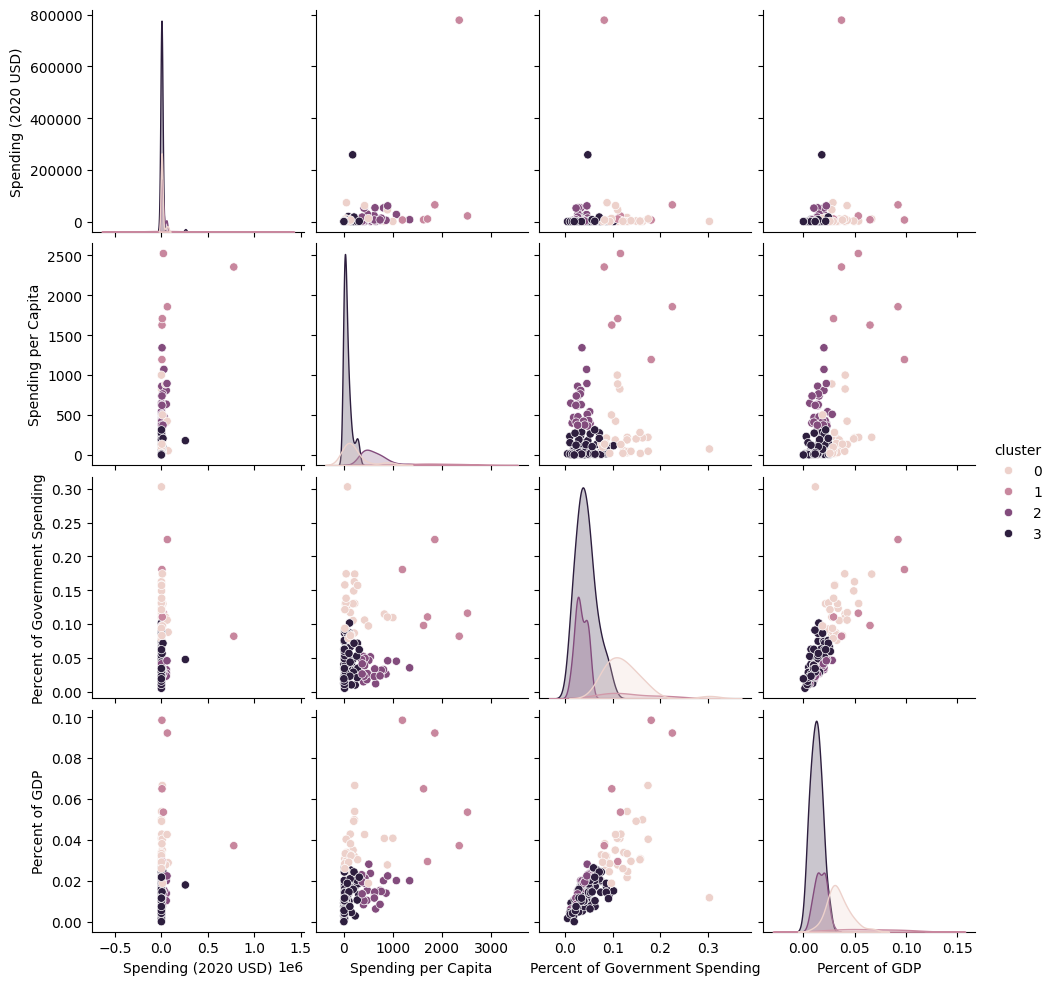

Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                      30.0    9073.543709   18135.032885   163.926877   
1                       6.0  147964.582042  309635.189564  6095.708713   
2                      26.0   15330.618681   18923.469359   405.790494   
3                      86.0    4513.543790   27841.230783     8.622460   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         522.737081   1663.090134   8646.648849   72937.064048   
1        7700.424616  15897.570598  53872.942442  778397.200000   
2        3176.345598   5857.060906  21818.934764   60675.039625   
3          81.022976    288.061512   1138.618231  257973.429834   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                      30.0   215.920971  ...                       0.136403   
1                       6.0  1875.150751  ...                       0.164503   
2                      26.0   612.677541  ...                       0.044645   
3                      86.0    70.290644  ...                       0.053006   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.303027           30.0  0.034105  0.011116  0.011742  0.027933   
1        0.225050            6.0  0.062634  0.028275  0.029429  0.041272   
2        0.052209           26.0  0.016585  0.005525  0.006273  0.013689   
3        0.101501           86.0  0.012481  0.005799  0.000054  0.007811   

                                       
              50%       75%       max  
cluster                                
0        0.032148  0.040637  0.066600  
1        0.059257  0.085398  0.098470  
2        0.015324  0.020431  0.028132  
3        0.012532  0.016783  0.026340  

[4 rows x 32 columns]

In [10]:
# Question 2.4
cols = ['Spending (2020 USD)', 'Spending per Capita',
        'Percent of Government Spending', 'Percent of GDP']
X = df[cols]
X = (X - X.min()) / (X.max() - X.min())

SSE = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, n_init=10).fit(X)
    SSE.append(model.inertia_)
plt.plot(range(1, 11), SSE, marker='o')
plt.title('Scree Plot')
plt.show()

model = KMeans(n_clusters=4, n_init=10).fit(X)
df['cluster'] = model.labels_

sns.pairplot(df[cols + ['cluster']], hue='cluster')
plt.show()

df.groupby('cluster')[cols].describe()

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]